# Calculating π Through Elastic Collisions — Phase Space

A small ball (mass $m$) sits between a wall and a big ball (mass $M = 100^{n-1}m$) sliding toward it. Every collision is perfectly elastic. Counting every collision (ball-ball **and** ball-wall) gives the first $n$ digits of π.

This notebook:
1. counts the collisions, comparing our original pure-Python loop against the optimized engine in `pi_collisions.py`;
2. plots each collision in **phase space**, where the circle (and the π) comes from.

In [1]:
import time

import matplotlib.pyplot as plt

from pi_collisions import count_collisions, phase_space_points

## 1. Counting collisions

Only the velocities matter for the count, so there's no need to track positions or time. After each ball-ball collision the new velocities come from conservation of momentum and kinetic energy:

$$v_1' = \frac{m_1 - m_2}{m_1 + m_2}v_1 + \frac{2m_2}{m_1 + m_2}v_2, \qquad v_2' = \frac{m_2 - m_1}{m_1 + m_2}v_2 + \frac{2m_1}{m_1 + m_2}v_1$$

and a wall collision just flips $v_1 \to -v_1$. It stops once both balls move right and the big one is faster.

This is our original function, unchanged apart from comments:

In [2]:
def calculate_pi_collisions(n_digits):
    # Mass ratio: m2/m1 = 100^(n-1)
    m1 = 1  # Mass of the first ball
    m2 = 100**(n_digits - 1)  # Mass of the second ball

    # Initial velocities
    v1 = 0  # Ball 1 starts stationary
    v2 = -5  # Ball 2 moves toward Ball 1
    collisions = 0  # Count collisions

    while True:
        # Check for collision between the balls
        if v2 < v1:
            collisions += 1
            # Update velocities using elastic collision formulas
            new_v1 = ((m1 - m2) / (m1 + m2)) * v1 + (2 * m2 / (m1 + m2)) * v2
            new_v2 = ((m2 - m1) / (m1 + m2)) * v2 + (2 * m1 / (m1 + m2)) * v1
            v1, v2 = new_v1, new_v2

        # Check for collision with the wall (Ball 1 hitting wall)
        if v1 < 0:
            collisions += 1
            v1 = -v1  # Reverse velocity of Ball 1

        # Stop if Ball 2 is moving away from Ball 1
        if v2 >= v1:
            break

    return collisions

`count_collisions` in `pi_collisions.py` runs the same loop, compiled to machine code with [numba](https://numba.pydata.org/). The pure-Python version is only timed up to $n = 7$ (3 million collisions); after that it takes too long to be worth waiting for.

In [3]:
count_collisions(1)  # first call compiles the function; don't count that in the timings

PI_DIGITS = "314159265"
print(f"{'n':>2} {'collisions':>13} {'matches pi':>11} {'python':>10} {'numba':>10} {'speedup':>8}")
for n_digits in range(1, 10):
    start = time.perf_counter()
    fast = count_collisions(n_digits)
    t_fast = time.perf_counter() - start

    if n_digits <= 7:
        start = time.perf_counter()
        slow = calculate_pi_collisions(n_digits)
        t_slow = time.perf_counter() - start
        assert slow == fast
        python_col, speedup_col = f"{t_slow:9.3f}s", f"{t_slow / t_fast:7.0f}x"
    else:
        python_col, speedup_col = f"{'-':>10}", f"{'-':>8}"

    matches = fast == int(PI_DIGITS[:n_digits])
    print(f"{n_digits:>2} {fast:>13,} {str(matches):>11} {python_col} {t_fast:9.4f}s {speedup_col}")

 n    collisions  matches pi     python      numba  speedup
 1             3        True     0.000s    0.0000s       3x
 2            31        True     0.000s    0.0000s       7x
 3           314        True     0.000s    0.0000s      26x
 4         3,141        True     0.001s    0.0000s      35x
 5        31,415        True     0.006s    0.0002s      37x
 6       314,159        True     0.065s    0.0015s      43x


 7     3,141,592        True     0.705s    0.0154s      46x
 8    31,415,926        True          -    0.1554s        -


 9   314,159,265        True          -    1.5422s        -


## 2. Phase space

Plot each state as the point $(x, y) = (\sqrt{M}\,v_2,\ \sqrt{m}\,v_1)$. Kinetic energy $\tfrac12 Mv_2^2 + \tfrac12 mv_1^2$ is conserved, so **every point lies on a circle** of radius $\sqrt{M}\,|v_0|$.

- A wall bounce flips $v_1$: a vertical jump.
- A ball-ball collision conserves momentum: a step along a line of slope $-\sqrt{M/m}$.

Each collision moves the point by the same angle around the circle ($2\theta$ per pair, $\theta = \arctan\sqrt{m/M}$), so about $\pi/\theta$ collisions fit before the balls separate. With $M/m = 100^{n-1}$, $\theta \approx 10^{-(n-1)}$, which is where the digits of π come from.

`phase_space_points` returns the point after every collision. For large $n$ there are millions, so `max_points` keeps every k-th one.

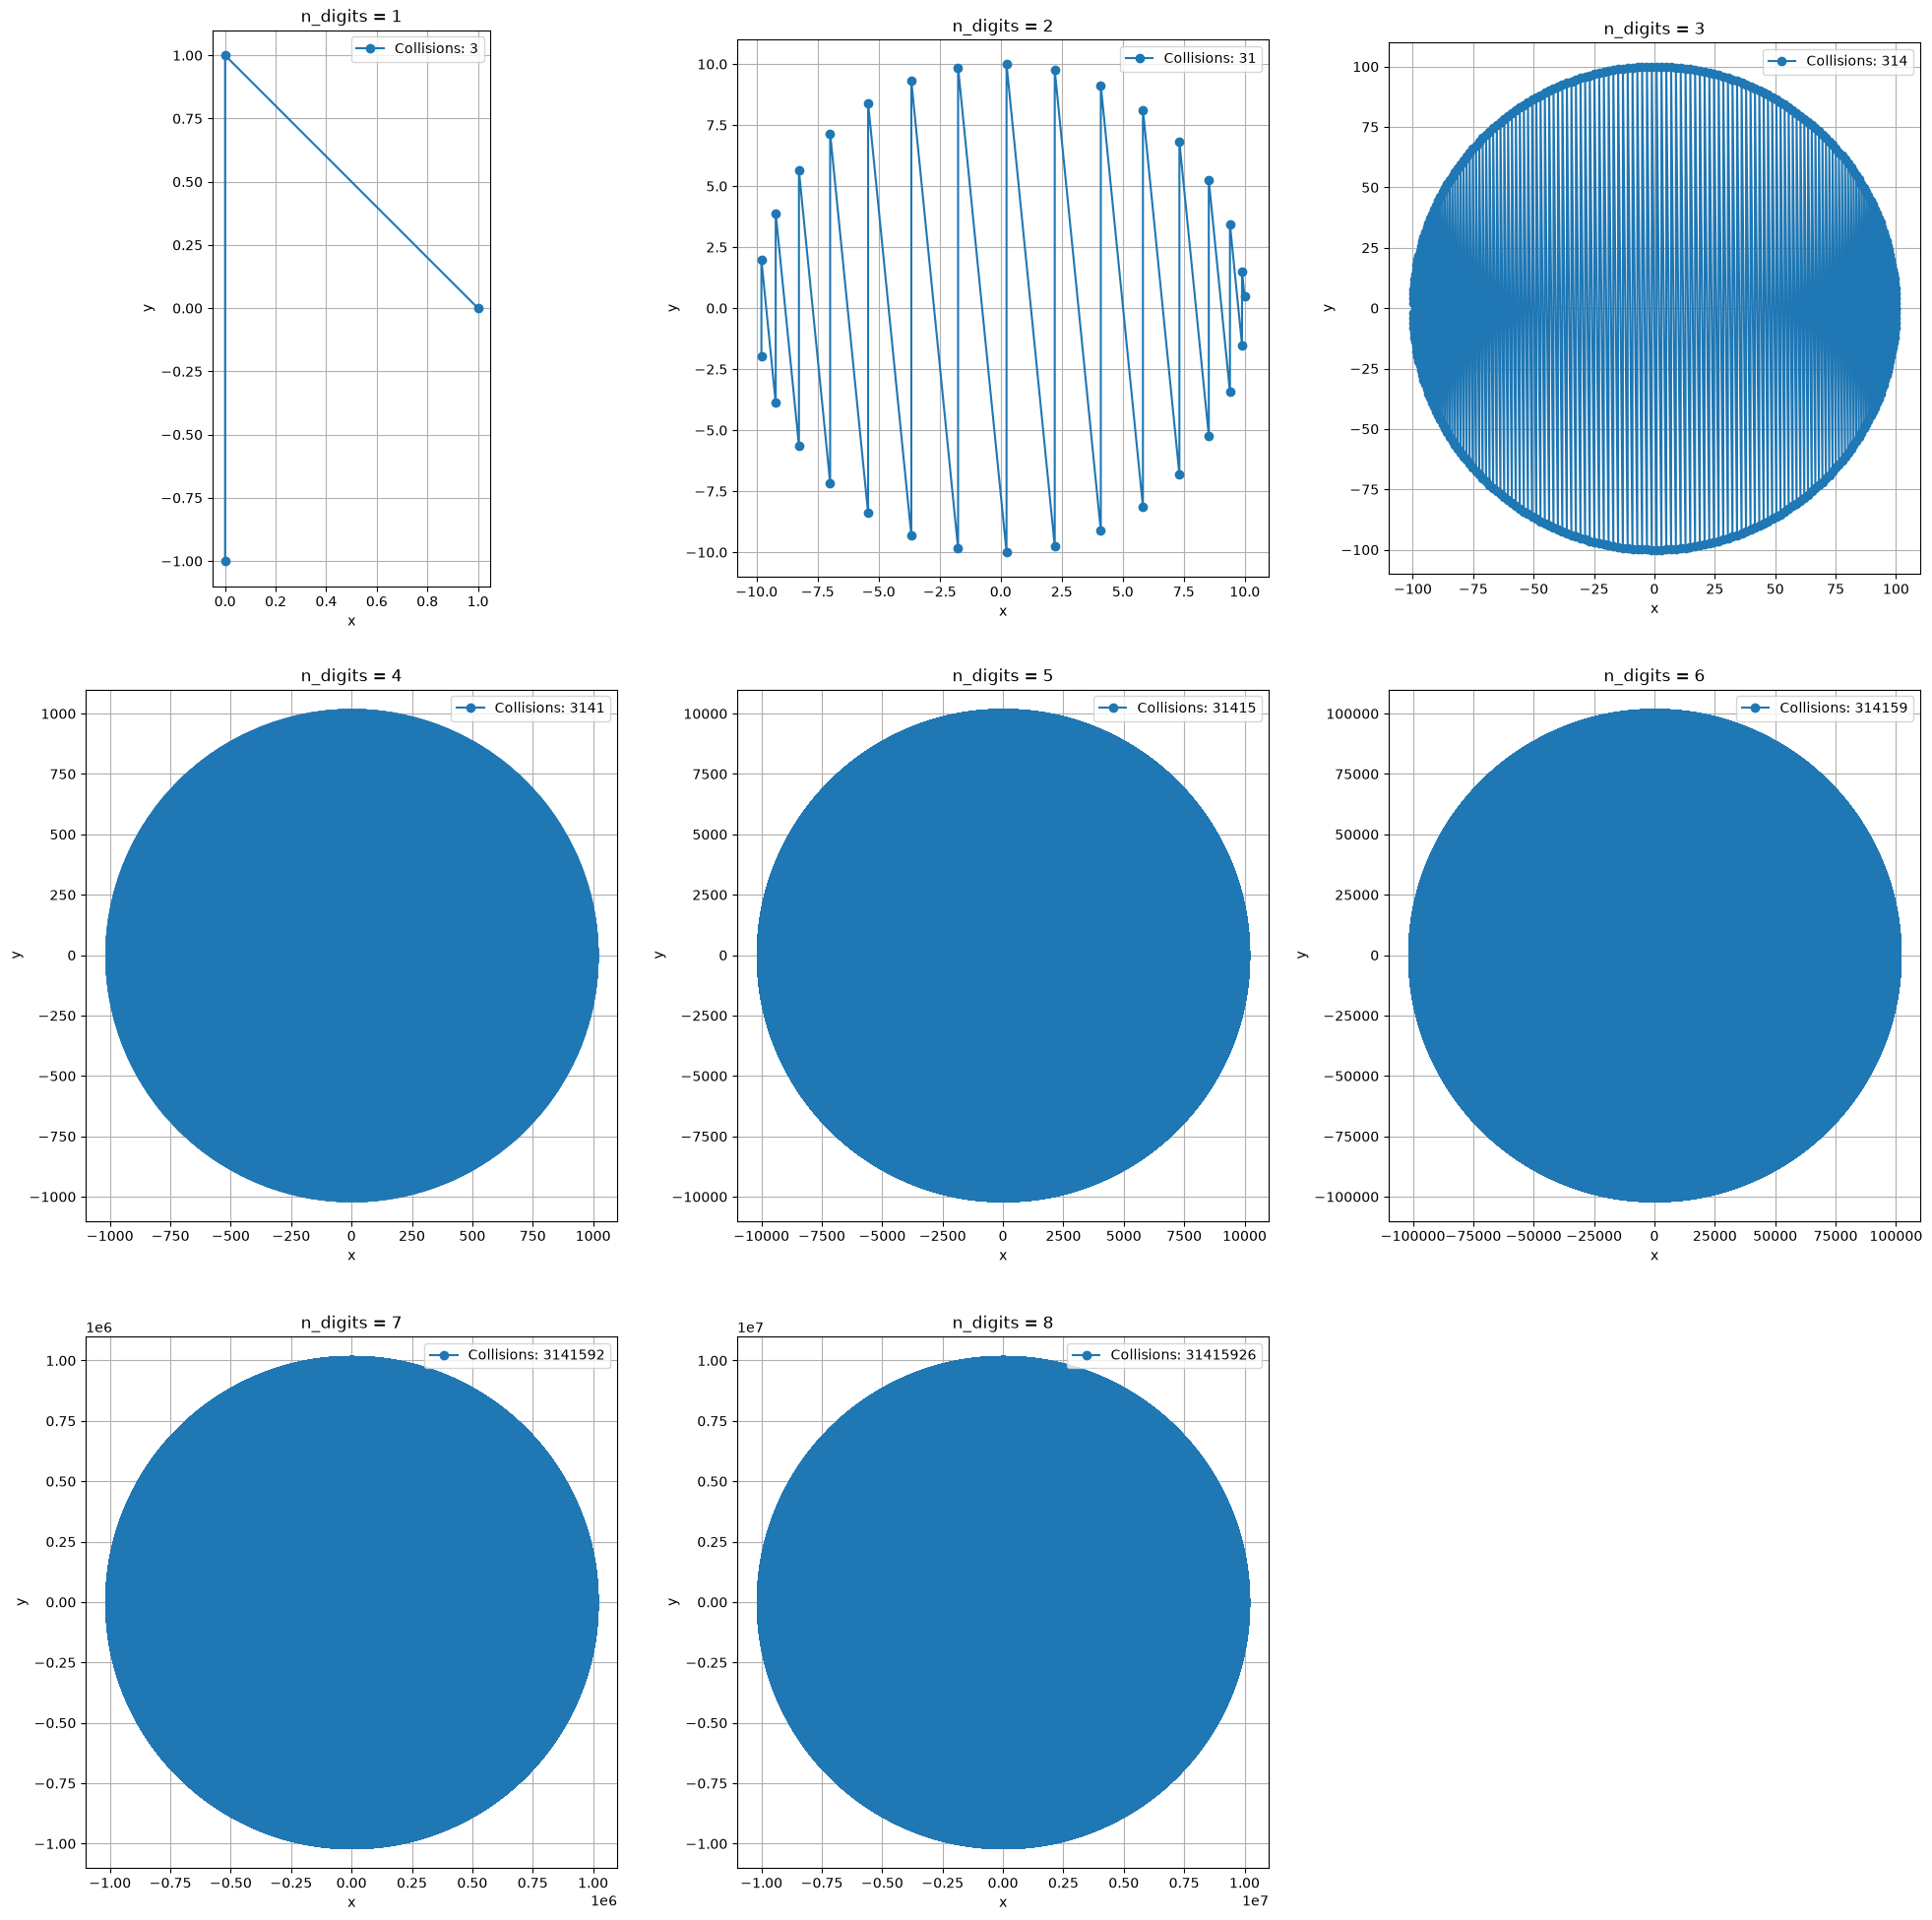

In [4]:
# Create the figure with gridspec
fig = plt.figure(figsize=(20, 20))  # Fixed figure size
gs = fig.add_gridspec(3, 3)  # 3x3 grid of subplots

# Loop over n_digits to plot each subplot
for n_digits in range(1, 9):
    x_values, y_values, pi_collisions = phase_space_points(n_digits, max_points=20_000)

    # Get the row and column for each subplot
    row = (n_digits - 1) // 3
    col = (n_digits - 1) % 3

    # Create the subplot in the specified grid location
    ax = fig.add_subplot(gs[row, col])

    # Plot the results
    ax.plot(x_values, y_values, marker='o', label=f"Collisions: {pi_collisions}")
    ax.set_title(f"n_digits = {n_digits}")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.legend(loc="upper right")
    ax.grid(True)

    # Set the aspect ratio to 'equal' so that circles look correct
    ax.set_aspect('equal', adjustable='box')

# Adjust layout to prevent overlap
plt.tight_layout(pad=2.0)
plt.show()

## 3. A single run

Change `n_digits` to look at one case on its own. Small values like 2 show the zig-zag clearly; from 3 up the lines fill the circle in.

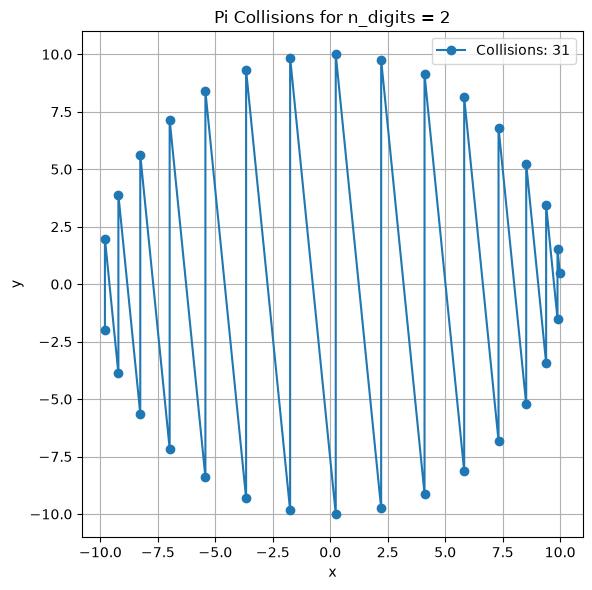

In [5]:
n_digits = 2
x_values, y_values, pi_collisions = phase_space_points(n_digits, max_points=20_000)

plt.figure(figsize=(6, 6))
plt.plot(x_values, y_values, marker='o', label=f"Collisions: {pi_collisions}")
plt.title(f"Pi Collisions for n_digits = {n_digits}")
plt.xlabel("x")
plt.ylabel("y")
plt.legend(loc="upper right")
plt.grid(True)
plt.gca().set_aspect('equal', adjustable='box')  # Make sure circles look correct
plt.tight_layout()
plt.show()